# Monte Carlo Simulations for Option Pricing

## Overview

This notebook implements Monte Carlo simulations as a method to determine the price of options, a financial instrument, in a Black-Scholes setting. The goal is to study Monte Carlo simulations as a numerical method for finance in a single workflow. 

We will focus on: 

• Pricing a European call option using Monte Carlo simulations and compare it to the Black Scholes formula 

• Extending the study to Asian options, which makes sense because they're path dependent, and we're computing paths

• Using historical data to analyze the feasibility of our models in real world settings

• Study the convergence and error of the Monte Carlo estimators


RNG seed: 42


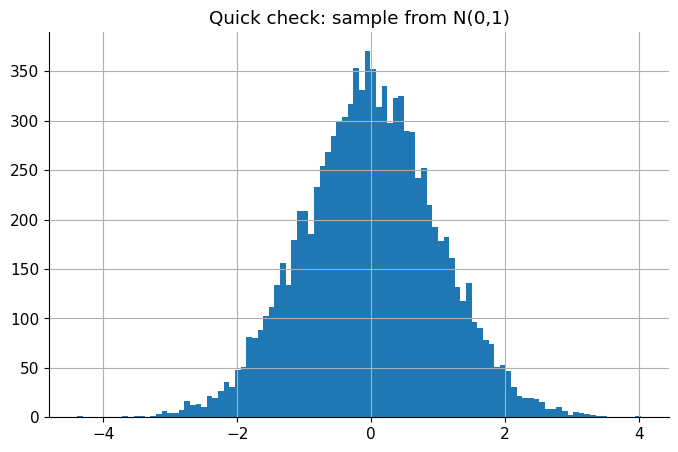

Test standard normals (first 5 draws):
[ 0.3047 -1.04    0.7505  0.9406 -1.951 ]


In [92]:
# Cell 1: Import libraries and configure settings

import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt
import math
import yfinance as yf


# Configure global plotting style

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 11


# Generate random numbers with a fixed seed 

rng_seed = 42  # fixed seed for reproducibility
rng = np.random.default_rng(rng_seed)

# Quick smoke test to verify normal distribution sampling
test_normals = rng.normal(loc=0.0, scale=1.0, size=10000)

print("RNG seed:", rng_seed)

# some visuals to see the bell
plt.hist(test_normals, bins=100)
plt.title("Quick check: sample from N(0,1)")
plt.show()

print("Test standard normals (first 5 draws):")
print(np.round(test_normals[:5], 4))


## European Call

In [93]:
# Cell 2: Define model parameters and simulation settings for European option pricing

# Black–Scholes model parameters (not realistic, just for demonstration)
S0    = 100.0   # initial stock price
K     = 100.0   # strike price
r     = 0.05    # risk-free rate (annual interest rate)
sigma = 0.20    # volatility (annual) - constant volatility model (never happens in reality!)
T     = 1.0     # maturity in years

# Monte Carlo sample sizes for convergence studies
N_grid = np.array([
     1_000,
     2_000,
     5_000,
    10_000,
    20_000,
    50_000,
   100_000,
   200_000,
   500_000,
 1_000_000
], dtype=int)


# Time discretization for path-based simulations (e.g. Asian option) 
# we want to have only trading days, so we set M = 252
M  = 252                    
dt = T / M                   # time step size


# full time grid for reference:
t_grid = np.linspace(0.0, T, M + 1)

# print outputs
print("Black–Scholes model parameters:")
print(f"  S0    = {S0}")
print(f"  K     = {K}")
print(f"  r     = {r}")
print(f"  sigma = {sigma}")
print(f"  T     = {T}")

print("\nMonte Carlo sample sizes N (convergence grid):")
print(" ", N_grid)

print("\nTime discretization for path-based simulations:")
print(f"  M  = {M} time steps")
print(f"  dt = {dt:.6f} years  (~{dt * 365:.2f} days)")


Black–Scholes model parameters:
  S0    = 100.0
  K     = 100.0
  r     = 0.05
  sigma = 0.2
  T     = 1.0

Monte Carlo sample sizes N (convergence grid):
  [   1000    2000    5000   10000   20000   50000  100000  200000  500000
 1000000]

Time discretization for path-based simulations:
  M  = 252 time steps
  dt = 0.003968 years  (~1.45 days)


In [94]:
# Cell 3: Compute the Black–Scholes analytic price for a European call option

# Black–Scholes analytic price for a European call

def norm_cdf(x):
    """
    Standard normal CDF Φ(x), implemented via the error function.
    Works for scalars or NumPy arrays.
    """
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0))) if np.isscalar(x) \
        else 0.5 * (1.0 + erf_vec(x))


erf_vec = np.vectorize(math.erf)

def bs_call_price(S0, K, r, sigma, T):
    """
    Black–Scholes price of a European call option.
    """
    if T <= 0:
        # At maturity, the price is just the payoff
        return max(S0 - K, 0.0)

    if sigma <= 0:
        # Degenerate case: zero volatility -> deterministic forward
        forward = S0 * math.exp(r * T)
        return math.exp(-r * T) * max(forward - K, 0.0)

    sqrtT = math.sqrt(T)
    d1 = (math.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    d2 = d1 - sigma * sqrtT

    price = S0 * norm_cdf(d1) - K * math.exp(-r * T) * norm_cdf(d2)
    return price, d1, d2


# Compute analytic benchmark price with current parameters from Cell 2
C_bs, d1, d2 = bs_call_price(S0, K, r, sigma, T)

# Store benchmark price for later comparison
bs_benchmark_call = C_bs

print("Black–Scholes analytic price for European call:")
print(f"  C_bs = {C_bs:.6f}")
print("Intermediate quantities:")
print(f"  d1 = {d1:.6f}")
print(f"  d2 = {d2:.6f}")


Black–Scholes analytic price for European call:
  C_bs = 10.450584
Intermediate quantities:
  d1 = 0.350000
  d2 = 0.150000


Simple Monte Carlo pricing of European call
  N = 5000
  MC estimate C_hat       = 10.321493
  Std. error SE(C_hat)    = 0.211341
  Analytic benchmark C_bs = 10.450584


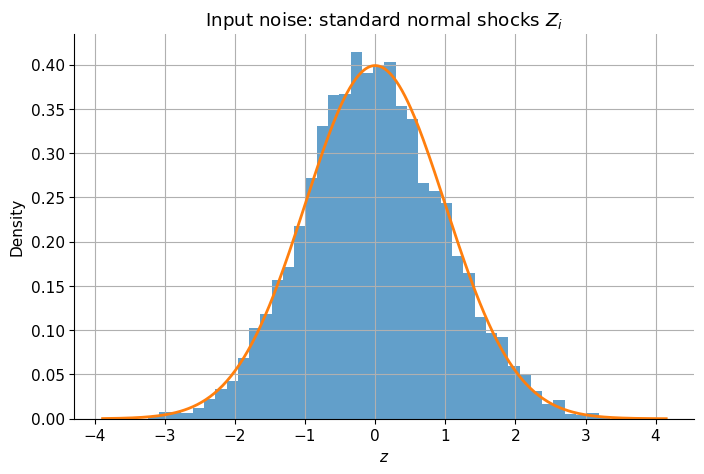

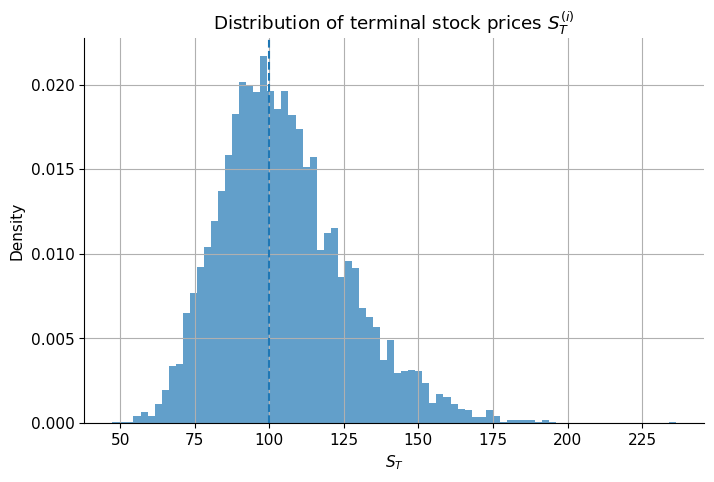

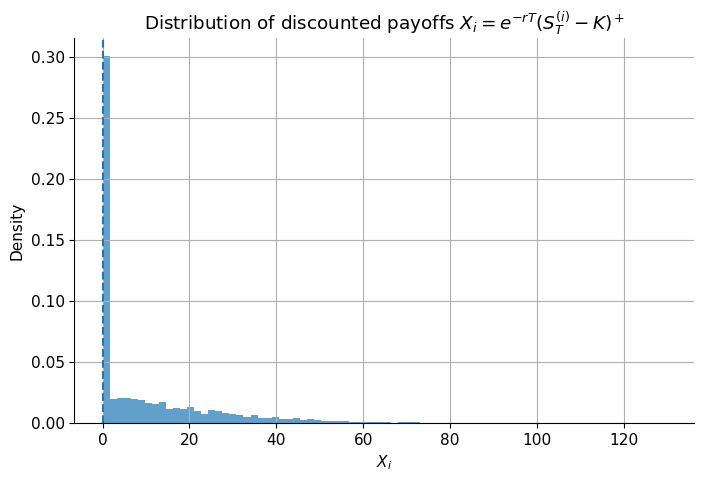

In [95]:
# Cell 4: Define functions for Monte Carlo pricing of European call option

# Simulation of terminal prices and Monte Carlo pricing

def mc_european_call_price(N, rng):
    """
    Plain Monte Carlo estimator for a European call under Black–Scholes.

    Implements:
        Z_i ~ N(0,1)
        S_T^(i) = S0 * exp((r - 0.5*sigma**2)*T + sigma*sqrt(T)*Z_i)
        X_i = exp(-r*T) * max(S_T^(i) - K, 0)
        C_hat = (1/N) * sum_i X_i
        SE(C_hat) = s_X / sqrt(N)
    """
    # 1) Generate Z_i
    Z = rng.normal(loc=0.0, scale=1.0, size=N)

    # 2) Map to terminal prices S_T^(i)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)

    # 3) Discounted payoffs X_i
    Xi = np.exp(-r * T) * np.maximum(ST - K, 0.0)

    # 4) Monte Carlo estimator and standard error
    C_hat = Xi.mean()
    s_X = Xi.std(ddof=1)           # sample standard deviation as volatility
    se_hat = s_X / np.sqrt(N)

    return C_hat, se_hat, Z, ST, Xi


# Use one N = 5,000 for a first test
N_test = N_grid[2] 

C_hat, se_hat, Z_test, ST_test, Xi_test = mc_european_call_price(N_test, rng)

print("Simple Monte Carlo pricing of European call")
print(f"  N = {N_test}")
print(f"  MC estimate C_hat       = {C_hat:.6f}")
print(f"  Std. error SE(C_hat)    = {se_hat:.6f}")
print(f"  Analytic benchmark C_bs = {bs_benchmark_call:.6f}")


# Plots of distributions:

# Histogram of Z_i with standard normal pdf
z_min, z_max = Z_test.min(), Z_test.max()
z_grid = np.linspace(z_min, z_max, 400)
normal_pdf = (1.0 / np.sqrt(2.0 * np.pi)) * np.exp(-0.5 * z_grid**2)

plt.figure()
plt.hist(Z_test, bins=50, density=True, alpha=0.7)
plt.plot(z_grid, normal_pdf, linewidth=2)
plt.title("Input noise: standard normal shocks $Z_i$")
plt.xlabel("$z$")
plt.ylabel("Density")
plt.show()

# Histogram of terminal prices S_T
plt.figure()
plt.hist(ST_test, bins=80, density=True, alpha=0.7)
plt.axvline(K, linestyle="--")  # show strike for reference
plt.title("Distribution of terminal stock prices $S_T^{(i)}$")
plt.xlabel("$S_T$")
plt.ylabel("Density")
plt.show()

# Histogram of discounted payoffs X_i
plt.figure()
plt.hist(Xi_test, bins=80, density=True, alpha=0.7)
plt.axvline(0.0, linestyle="--")
plt.title("Distribution of discounted payoffs $X_i = e^{-rT}(S_T^{(i)} - K)^+$")
plt.xlabel("$X_i$")
plt.ylabel("Density")
plt.show()


Convergence of Monte Carlo estimator for European call
      N     C_hat       SE rel_error
   1000  9.911980 0.448345   -5.154%
   2000  9.732904 0.315045   -6.867%
   5000 10.168920 0.205861   -2.695%
  10000 10.345182 0.147663   -1.009%
  20000 10.544517 0.105179   +0.899%
  50000 10.457692 0.066143   +0.068%
 100000 10.420541 0.046770   -0.287%
 200000 10.463414 0.033118   +0.123%
 500000 10.450050 0.020856   -0.005%
1000000 10.453195 0.014731   +0.025%


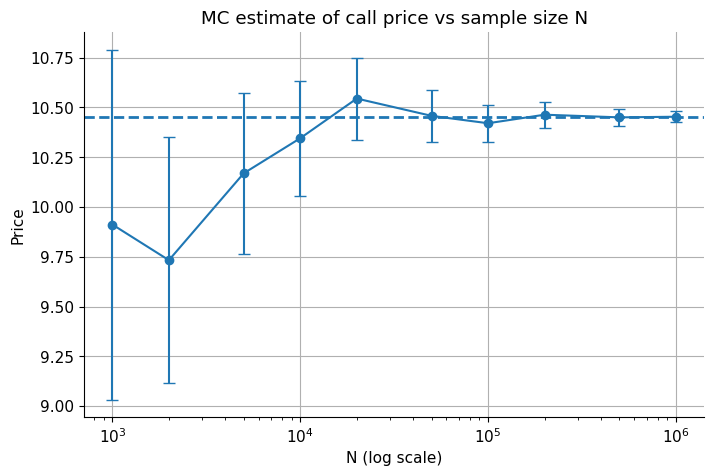

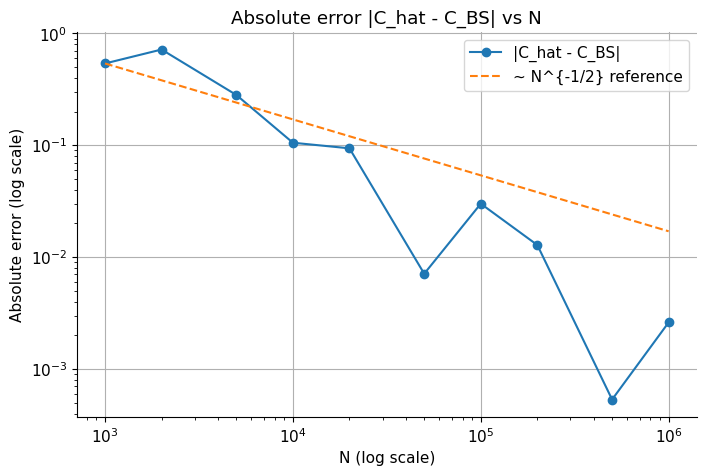

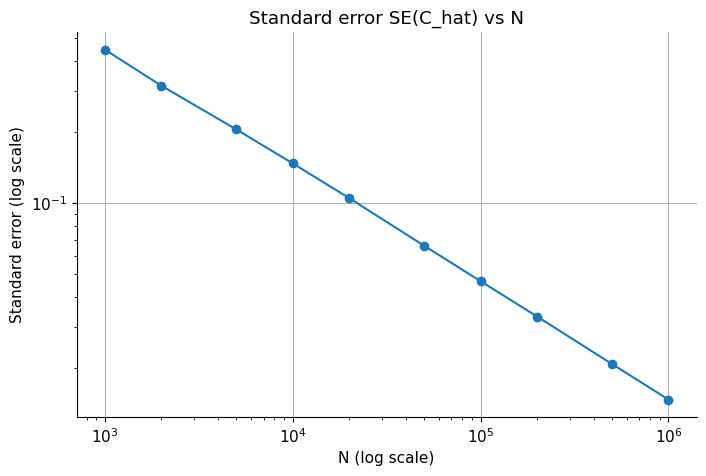

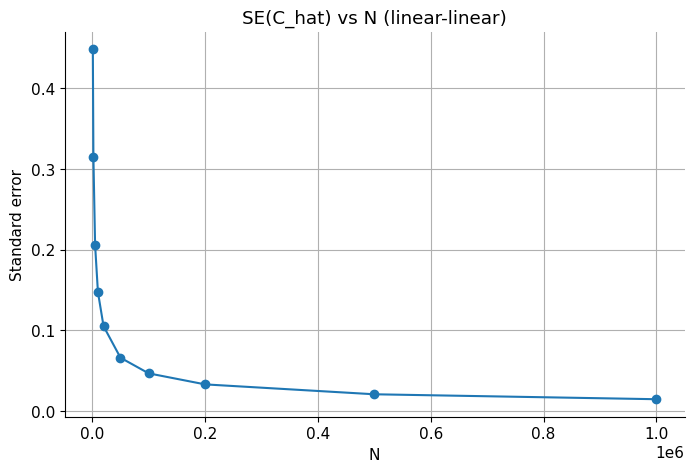

In [96]:
# Cell 5: Convergence study of Monte Carlo estimator with increasing N

# 1) Use a fresh RNG for this experiment so it's reproducible & self-contained
rng_eur = np.random.default_rng(rng_seed + 0)

# Largest sample size (up to 1e6)
N_max = int(N_grid[-1])

# 2) Generate ONE large batch of shocks, prices and payoffs
Z_all = rng_eur.normal(loc=0.0, scale=1.0, size=N_max)
ST_all = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z_all)
Xi_all = np.exp(-r * T) * np.maximum(ST_all - K, 0.0)

# 3) Compute C_hat and SE for each N using the first N payoffs
records = []

for N in N_grid:
    N = int(N)
    Xi_N = Xi_all[:N]

    C_hat_N = Xi_N.mean()
    s_X_N = Xi_N.std(ddof=1)
    se_N = s_X_N / np.sqrt(N)
    rel_error_N = (C_hat_N - bs_benchmark_call) / bs_benchmark_call

    records.append((N, C_hat_N, se_N, rel_error_N))

results_df = pd.DataFrame(
    records,
    columns=["N", "C_hat", "SE", "rel_error"]
)

print("Convergence of Monte Carlo estimator for European call")
print(results_df.to_string(
    index=False,
    formatters={
        "N":        "{:d}".format,
        "C_hat":    "{:.6f}".format,
        "SE":       "{:.6f}".format,
        "rel_error":"{:+.3%}".format
    }
))

# 4) Visualization of convergence results

# Price vs N with 95% CI and analytic benchmark

plt.figure()
plt.errorbar(
    results_df["N"],
    results_df["C_hat"],
    yerr=1.96 * results_df["SE"],
    fmt="o-", capsize=4
)
plt.axhline(bs_benchmark_call, linestyle="--", linewidth=2)
plt.xscale("log")
plt.title("MC estimate of call price vs sample size N")
plt.xlabel("N (log scale)")
plt.ylabel("Price")
plt.show()


# 5) Absolute error vs N on log–log scale with ~N^{-1/2} reference

abs_error = np.abs(results_df["C_hat"] - bs_benchmark_call)

plt.figure()
plt.loglog(results_df["N"], abs_error, "o-", label="|C_hat - C_BS|")

# Add a rough reference line ~ 1/sqrt(N) through the first point
N_ref = results_df["N"].iloc[0]
err_ref = abs_error.iloc[0]
ref_line = err_ref * np.sqrt(N_ref / results_df["N"])
plt.loglog(results_df["N"], ref_line, "--", label="~ N^{-1/2} reference")

plt.title("Absolute error |C_hat - C_BS| vs N")
plt.xlabel("N (log scale)")
plt.ylabel("Absolute error (log scale)")
plt.legend()
plt.show()

# 6) Standard error vs N on log–log scale

plt.figure()
plt.loglog(results_df["N"], results_df["SE"], "o-")
plt.title("Standard error SE(C_hat) vs N")
plt.xlabel("N (log scale)")
plt.ylabel("Standard error (log scale)")
plt.show()


# 7) Standard error vs N on linear-linear scale . (Order should be O(N^{-1/2}) but linear-linear is easier to interpret magnitude.)
plt.figure()
plt.plot(results_df["N"], results_df["SE"], "o-")
plt.title("SE(C_hat) vs N (linear-linear)")
plt.xlabel("N")
plt.ylabel("Standard error")
plt.show()




## Asian call

Simulated GBM paths:
  paths.shape = (200000, 253)
  First path, first 5 values: [100.     100.3201 101.193  100.4612  99.3295]

Arithmetic Asian call (discrete average over t_1,...,t_M)
  N_paths        = 200000
  MC price       = 5.818343
  Std. error     = 0.017999


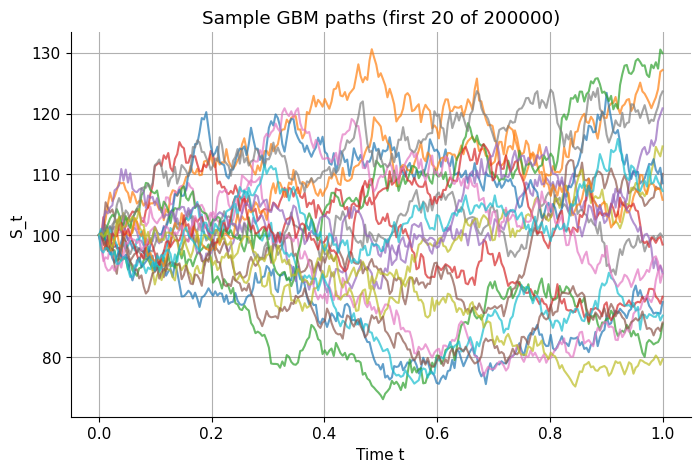

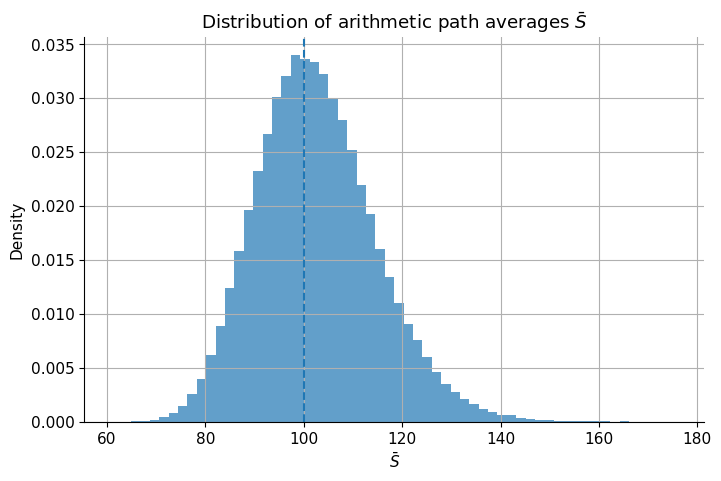

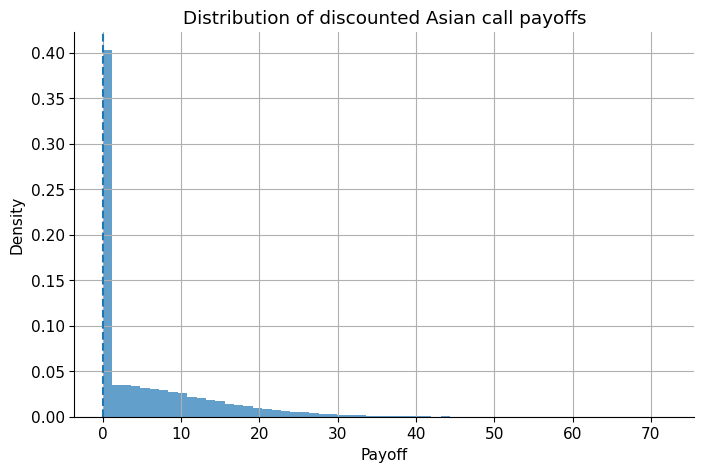

In [98]:
# Cell 6: Monte Carlo pricing of an arithmetic Asian call option

def simulate_gbm_paths(S0, r, sigma, T, M, N_paths, rng):
    """
    Simulate GBM paths using log-increments:
        S_{t_{k+1}} = S_{t_k} * exp( (r - 0.5*sigma^2)*dt + sigma*sqrt(dt)*Z_{k} )

    Args:
        S0      : initial stock price
        r       : risk-free rate
        sigma   : volatility
        T       : maturity (years)
        M       : number of time steps
        N_paths : number of simulated paths
        rng     : NumPy Generator

    Returns:
        t_grid  : array of shape (M+1,) with time points 0,...,T
        paths   : array of shape (N_paths, M+1) with simulated GBM paths
    """
    dt = T / M
    t_grid = np.linspace(0.0, T, M + 1)

    # Standard normal shocks for each step and each path
    Z = rng.normal(loc=0.0, scale=1.0, size=(N_paths, M))

    # Log-increments of GBM
    drift = (r - 0.5 * sigma**2) * dt
    diffusion = sigma * np.sqrt(dt)
    log_increments = drift + diffusion * Z              # (N_paths, M)

    # Cumulative log-returns along each path
    log_paths = np.cumsum(log_increments, axis=1)       # (N_paths, M)
    log_S0 = np.log(S0)

    # Prepend time-0 value
    log_paths = np.concatenate(
        [np.full((N_paths, 1), log_S0), log_S0 + log_paths],
        axis=1
    )

    paths = np.exp(log_paths)
    return t_grid, paths


def price_asian_call_from_paths(paths, K, r, T, average_from=1):
    """
    Price an arithmetic Asian call from pre-simulated GBM paths.

    Args:
        paths       : array (N_paths, M+1) of GBM paths
        K           : strike
        r           : risk-free rate
        T           : maturity
        average_from: index in time dimension from which to start averaging
                      (default 1 -> average t_1,...,t_M, excluding t_0)

    Returns:
        price       : Monte Carlo price estimate
        se          : standard error of estimator
        S_avg       : path-wise arithmetic averages (N_paths,)
        payoffs     : discounted payoffs (N_paths,)
    """
    # Arithmetic average along each path over chosen time points
    S_avg = paths[:, average_from:].mean(axis=1)

    # Discounted Asian call payoff
    payoffs = np.exp(-r * T) * np.maximum(S_avg - K, 0.0)

    price = payoffs.mean()
    se = payoffs.std(ddof=1) / np.sqrt(len(payoffs))

    return price, se, S_avg, payoffs


# ----- Simulation + pricing -----

# Fresh RNG for this cell
rng_asian = np.random.default_rng(rng_seed + 1)

# Number of paths for pricing
N_paths_asian = N_grid[-3]  # e.g., 200,000

t_grid, paths = simulate_gbm_paths(S0, r, sigma, T, M, N_paths_asian, rng_asian)

print("Simulated GBM paths:")
print(f"  paths.shape = {paths.shape}")  # (N_paths_asian, M+1)
print(f"  First path, first 5 values: {np.round(paths[0, :5], 4)}")

asian_price, asian_se, S_avg, asian_payoffs = price_asian_call_from_paths(
    paths, K, r, T, average_from=1
)

print("\nArithmetic Asian call (discrete average over t_1,...,t_M)")
print(f"  N_paths        = {N_paths_asian}")
print(f"  MC price       = {asian_price:.6f}")
print(f"  Std. error     = {asian_se:.6f}")


# ----- Plots for intuition -----

# A few sample paths
N_paths_plot = 20
plt.figure()
for i in range(N_paths_plot):
    plt.plot(t_grid, paths[i], alpha=0.7)
plt.title(f"Sample GBM paths (first {N_paths_plot} of {N_paths_asian})")
plt.xlabel("Time t")
plt.ylabel("S_t")
plt.show()

# Histogram of path averages S_avg
plt.figure()
plt.hist(S_avg, bins=60, density=True, alpha=0.7)
plt.axvline(K, linestyle="--")   # strike as reference
plt.title("Distribution of arithmetic path averages $\\bar S$")
plt.xlabel("$\\bar S$")
plt.ylabel("Density")
plt.show()

# Histogram of discounted Asian payoffs
plt.figure()
plt.hist(asian_payoffs, bins=60, density=True, alpha=0.7)
plt.axvline(0.0, linestyle="--")
plt.title("Distribution of discounted Asian call payoffs")
plt.xlabel("Payoff")
plt.ylabel("Density")
plt.show()


Convergence of arithmetic Asian call price in M (discretization study)
   M    price       SE abs_error_vs_ref
  16 6.046313 0.018659         0.275153
  32 5.876889 0.018224         0.105729
  64 5.848025 0.018052         0.076865
 126 5.813672 0.017960         0.042512
 252 5.758028 0.017828         0.013132
 504 5.750807 0.017852         0.020353
1008 5.771160 0.017908         0.000000

Reference price (M = 1008) ≈ 5.771160


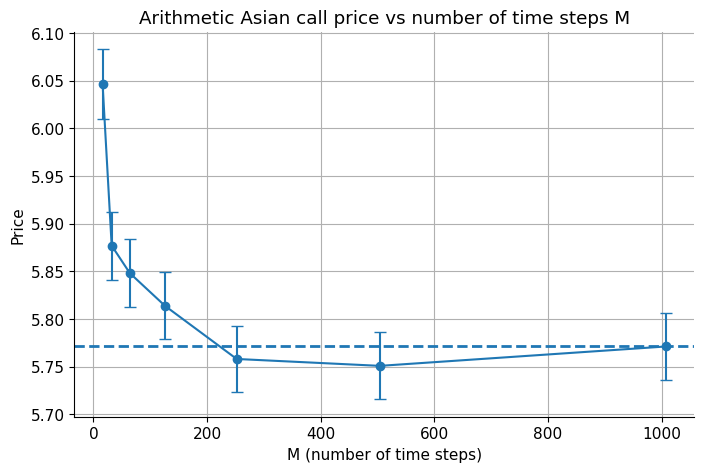

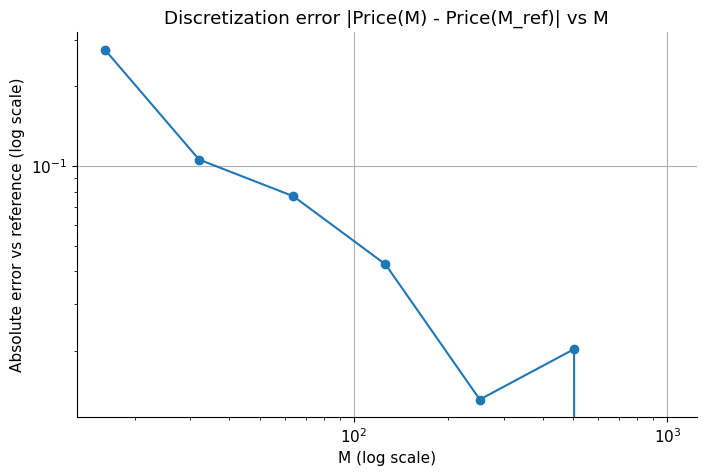

In [99]:
# Cell 7: Convergence study of Asian call price with increasing M

# Grid of time steps M (coarser -> finer)
M_grid = np.array([16, 32, 64, 126, 252, 504, 1008])

rng_M = rng_asian  # reuse RNG from previous cell

records_M = []

for M_val in M_grid:
    M_val = int(M_val)
    t_grid_M, paths_M = simulate_gbm_paths(S0, r, sigma, T, M_val, N_paths_asian, rng_M)
    price_M, se_M, S_avg_M, payoffs_M = price_asian_call_from_paths(
        paths_M, K, r, T, average_from=1
    )
    records_M.append((M_val, price_M, se_M))

results_M = pd.DataFrame(records_M, columns=["M", "price", "SE"])

# Take largest M as "reference" (quasi-continuous)
ref_price = results_M["price"].iloc[-1]

results_M["abs_error_vs_ref"] = np.abs(results_M["price"] - ref_price)

print("Convergence of arithmetic Asian call price in M (discretization study)")
print(results_M.to_string(
    index=False,
    formatters={
        "M":               "{:d}".format,
        "price":           "{:.6f}".format,
        "SE":              "{:.6f}".format,
        "abs_error_vs_ref":"{:.6f}".format
    }
))
print(f"\nReference price (M = {int(M_grid[-1])}) ≈ {ref_price:.6f}")

# 1) Price vs M with error bars
plt.figure()
plt.errorbar(
    results_M["M"],
    results_M["price"],
    yerr=1.96 * results_M["SE"],
    fmt="o-",
    capsize=4
)
plt.axhline(ref_price, linestyle="--", linewidth=2)
plt.title("Arithmetic Asian call price vs number of time steps M")
plt.xlabel("M (number of time steps)")
plt.ylabel("Price")
plt.show()

# 2) Absolute error vs M on log–log scale
plt.figure()
plt.loglog(results_M["M"], results_M["abs_error_vs_ref"], "o-")
plt.title("Discretization error |Price(M) - Price(M_ref)| vs M")
plt.xlabel("M (log scale)")
plt.ylabel("Absolute error vs reference (log scale)")
plt.show()


In [100]:
# Cell 8: Control variate technique using geometric Asian call option

def geo_asian_call_discrete(S0, K, r, sigma, T, n):
    """
    Closed-form price of a *discrete* geometric Asian call with n equally spaced fixings.
    Uses the Kemna–Vorst-style formula.
    """
    # Effective variance of log(geometric average)
    sigma_n2 = sigma**2 * (n + 1) * (2*n + 1) / (6 * n**2)
    sigma_n = math.sqrt(sigma_n2)

    # Effective drift of log(geometric average)
    mu_n = (r - 0.5 * sigma**2) * (n + 1) / (2 * n) + 0.5 * sigma_n2

    d1 = (math.log(S0 / K) + (mu_n + 0.5 * sigma_n2) * T) / (sigma_n * math.sqrt(T))
    d2 = d1 - sigma_n * math.sqrt(T)

    price = math.exp(-r * T) * (
        S0 * math.exp(mu_n * T) * norm_cdf(d1) - K * norm_cdf(d2)
    )
    return price





# Large N to see variance reduction
rng_cv = np.random.default_rng(rng_seed + 2)

# Simulate paths once
t_grid_cv, paths_cv = simulate_gbm_paths(S0, r, sigma, T, M, N_paths_asian, rng_cv)

# Arithmetic and geometric averages along the path (exclude t_0)
S_arith = paths_cv[:, 1:].mean(axis=1)
S_geo = np.exp(np.log(paths_cv[:, 1:]).mean(axis=1))

disc = np.exp(-r * T)

X = disc * np.maximum(S_arith - K, 0.0)  # arithmetic discounted payoff
Y = disc * np.maximum(S_geo - K, 0.0)    # geometric discounted payoff

# Plain MC estimator for arithmetic Asian
C_arith_mc = X.mean()
se_arith = X.std(ddof=1) / np.sqrt(N_paths_asian)

# Geometric Asian: analytic vs MC
C_geo_analytic = geo_asian_call_discrete(S0, K, r, sigma, T, M)
C_geo_mc = Y.mean()
se_geo_mc = Y.std(ddof=1) / np.sqrt(N_paths_asian)

# Control variate coefficient beta ~ Cov(X, Y) / Var(Y)
cov_XY = np.cov(X, Y, ddof=1)[0, 1]
var_Y = np.var(Y, ddof=1)
beta_hat = cov_XY / var_Y

# Per-path control variate payoff and estimator
X_cv = X + beta_hat * (C_geo_analytic - Y)
C_cv = X_cv.mean()
se_cv = X_cv.std(ddof=1) / np.sqrt(N_paths_asian)

corr_XY = np.corrcoef(X, Y)[0, 1]
var_reduction = (se_arith**2) / (se_cv**2)

print("Geometric Asian call (discrete, same fixing dates)")
print(f"  Analytic price            = {C_geo_analytic:.6f}")
print(f"  MC estimate (same paths)  = {C_geo_mc:.6f}  (SE ~ {se_geo_mc:.6f})")

print("\nArithmetic Asian call – plain MC vs control variate")
print(f"  N_paths                    = {N_paths_asian}")
print(f"  Plain MC price             = {C_arith_mc:.6f}")
print(f"  Plain MC SE                = {se_arith:.6f}")
print(f"  Control variate price      = {C_cv:.6f}")
print(f"  Control variate SE         = {se_cv:.6f}")
print(f"  Corr(X_arith, Y_geo)       = {corr_XY:.4f}")
print(f"  Variance reduction factor  ≈ {var_reduction:.2f}x")


Geometric Asian call (discrete, same fixing dates)
  Analytic price            = 5.565509
  MC estimate (same paths)  = 5.569751  (SE ~ 0.017314)

Arithmetic Asian call – plain MC vs control variate
  N_paths                    = 200000
  Plain MC price             = 5.786390
  Plain MC SE                = 0.017933
  Control variate price      = 5.781998
  Control variate SE         = 0.000494
  Corr(X_arith, Y_geo)       = 0.9996
  Variance reduction factor  ≈ 1318.24x


Single-path inspection
  Final stock price S_T      = 89.0385
  Final arithmetic average   = 86.5574
  Discounted Asian payoff    = 0.0000


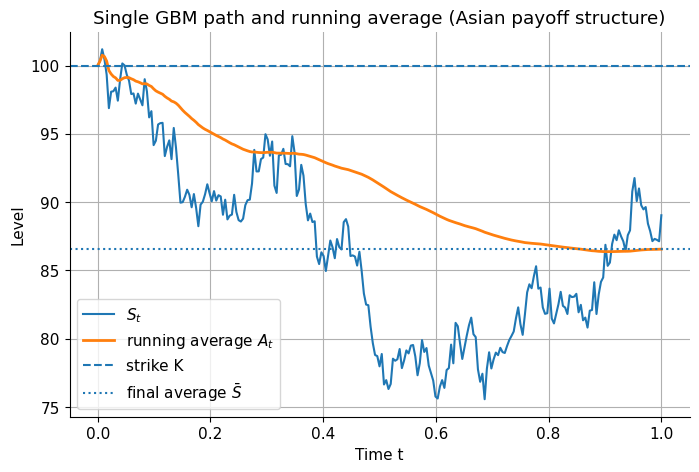

In [103]:
# Cell 9: Inspect a single GBM path and its running average for Asian payoff

# If paths/t_grid don't exist (e.g. you restarted), re-simulate:
# rng_paths = np.random.default_rng(rng_seed)
# N_paths_asian = 200_000
# t_grid, paths = simulate_gbm_paths(S0, r, sigma, T, M, N_paths_asian, rng_paths)

# Pick one representative path
idx = 0
path = paths[idx]              # shape (M+1,)

# Running average of S_t over t_1,...,t_M
running_avg = path[1:].cumsum() / np.arange(1, len(path))
running_avg_full = np.concatenate(([path[0]], running_avg))

final_avg = running_avg[-1]
asian_payoff = np.exp(-r * T) * max(final_avg - K, 0.0)

print("Single-path inspection")
print(f"  Final stock price S_T      = {path[-1]:.4f}")
print(f"  Final arithmetic average   = {final_avg:.4f}")
print(f"  Discounted Asian payoff    = {asian_payoff:.4f}")

plt.figure()
plt.plot(t_grid, path, label="$S_t$")
plt.plot(t_grid, running_avg_full, label="running average $A_t$", linewidth=2)
plt.axhline(K, linestyle="--", label="strike K")
plt.axhline(final_avg, linestyle=":", label="final average $\\bar S$")
plt.title("Single GBM path and running average (Asian payoff structure)")
plt.xlabel("Time t")
plt.ylabel("Level")
plt.legend()
plt.show()


Visualization cell:
  paths.shape = (200000, 253)


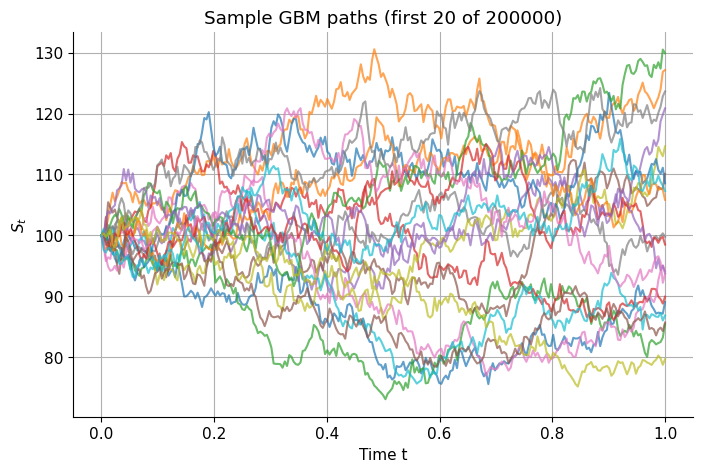

  Mean(S_T)   ≈ 105.1865
  Mean(S_avg) ≈ 102.5872


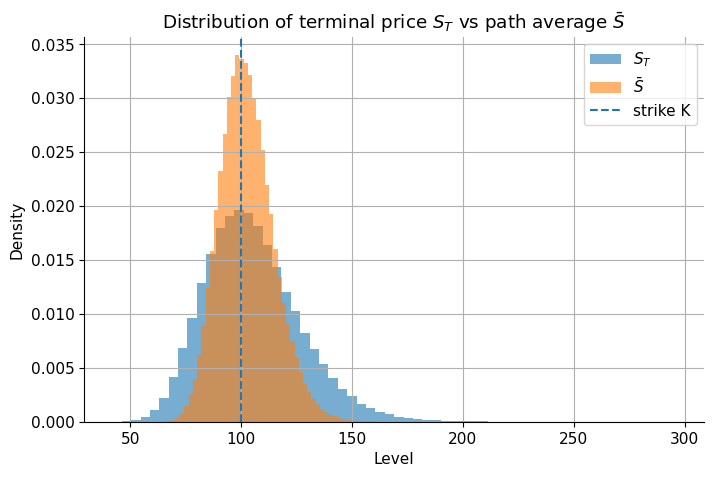

In [104]:
# # Cell 10: Visualize distribution of terminal prices vs path averages

# 1) Make sure we have GBM paths; if not, simulate them
try:
    paths
    t_grid
except NameError:
    rng_vis = np.random.default_rng(rng_seed + 3)
    N_paths_vis = N_paths_asian 
    t_grid, paths = simulate_gbm_paths(S0, r, sigma, T, M, N_paths_vis, rng_vis)

N_paths_total, M_plus_1 = paths.shape
print("Visualization cell:")
print(f"  paths.shape = {paths.shape}")

# 2) Plot a small number of sample paths
N_paths_plot = min(20, N_paths_total)

plt.figure()
for i in range(N_paths_plot):
    plt.plot(t_grid, paths[i], alpha=0.7)
plt.title(f"Sample GBM paths (first {N_paths_plot} of {N_paths_total})")
plt.xlabel("Time t")
plt.ylabel("$S_t$")
plt.show()

# 3) Compute terminal prices and path averages used in the Asian payoff
S_T_all = paths[:, -1]
S_avg_all = paths[:, 1:].mean(axis=1)   # average over t_1,...,t_M

print(f"  Mean(S_T)   ≈ {S_T_all.mean():.4f}")
print(f"  Mean(S_avg) ≈ {S_avg_all.mean():.4f}")

# 4) Histogram: S_T vs S_avg (showing narrower distribution of averages)
plt.figure()
plt.hist(S_T_all,  bins=60, density=True, alpha=0.6, label="$S_T$")
plt.hist(S_avg_all, bins=60, density=True, alpha=0.6, label="$\\bar S$")
plt.axvline(K, linestyle="--", label="strike K")
plt.title("Distribution of terminal price $S_T$ vs path average $\\bar S$")
plt.xlabel("Level")
plt.ylabel("Density")
plt.legend()
plt.show()



Reference Asian price (M=252, N_ref=1000000): 5.772948
  Reference MC standard error:                     0.008005


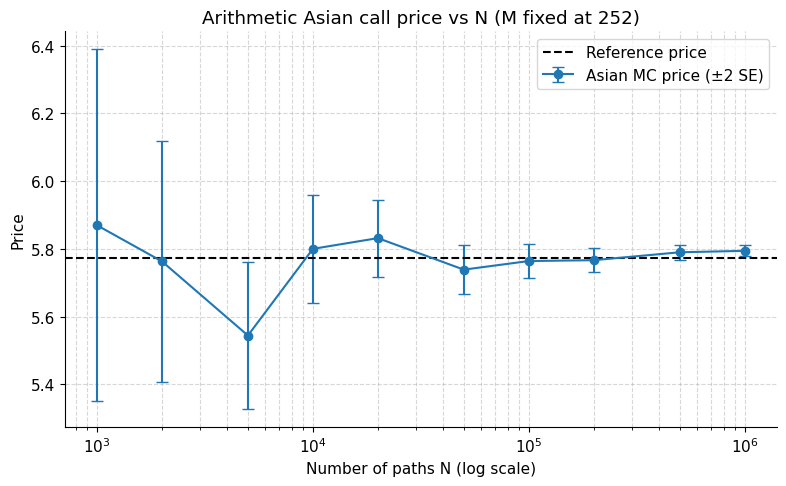

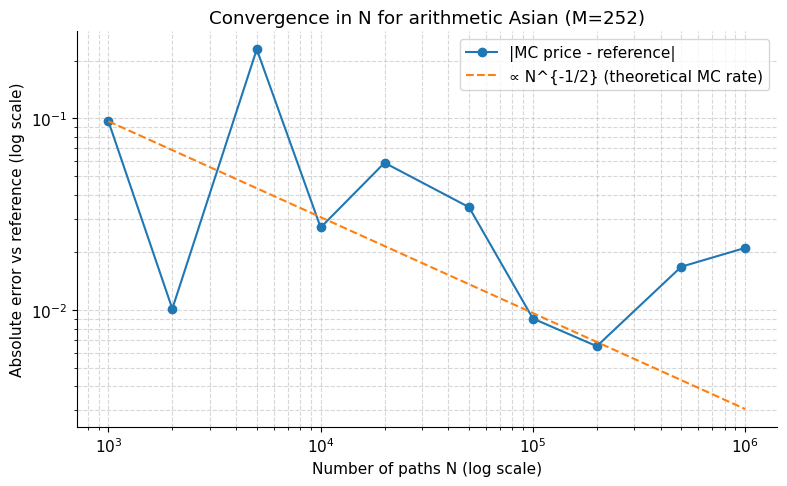

In [105]:
# # Cell 11: Convergence study of Asian call price in N (for fixed M)



# 1. Compute a "reference" price with large N_ref
N_ref = N_grid[-1]  # e.g., 1,000,000
rng_ref = np.random.default_rng(rng_seed + 4)

t_grid_ref, paths_ref = simulate_gbm_paths(
    S0=S0,
    r=r,
    sigma=sigma,
    T=T,
    M=M,
    N_paths=N_ref,
    rng=rng_ref
)

price_ref, se_ref, S_avg_ref, payoffs_ref = price_asian_call_from_paths(
    paths_ref, K=K, r=r, T=T
)

print(f"Reference Asian price (M={M}, N_ref={N_ref}): {price_ref:.6f}")
print(f"  Reference MC standard error:                     {se_ref:.6f}")

# 3. Now study convergence in N towards this reference

prices_N = []
ses_N = []
errors_N = []

for N_paths in N_grid:
    rng_tmp = np.random.default_rng(rng_seed + 5 + int(N_paths))

    t_grid_N, paths_N = simulate_gbm_paths(
        S0=S0,
        r=r,
        sigma=sigma,
        T=T,
        M=M,
        N_paths=N_paths,
        rng=rng_tmp
    )

    price_N, se_N, S_avg_N, payoffs_N = price_asian_call_from_paths(
        paths_N, K=K, r=r, T=T
    )

    prices_N.append(price_N)
    ses_N.append(se_N)
    errors_N.append(abs(price_N - price_ref))

prices_N = np.array(prices_N)
ses_N = np.array(ses_N)
errors_N = np.array(errors_N)

# 4. Plot price vs N with error bars
fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    N_grid, prices_N, yerr=2 * ses_N,
    fmt="o-", capsize=4, label="Asian MC price (±2 SE)"
)
ax.axhline(price_ref, linestyle="--", color="black", label="Reference price")

ax.set_xscale("log")
ax.set_xlabel("Number of paths N (log scale)")
ax.set_ylabel("Price")
ax.set_title(f"Arithmetic Asian call price vs N (M fixed at {M})")
ax.legend()
ax.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 5. Plot absolute error vs N in log–log with N^{-1/2} reference
fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(N_grid, errors_N, "o-", label="|MC price - reference|")

# Reference slope N^{-1/2} scaled to first error
ref_const = errors_N[0] * np.sqrt(N_grid[0])
ax.loglog(
    N_grid,
    ref_const / np.sqrt(N_grid),
    "--",
    label="∝ N^{-1/2} (theoretical MC rate)"
)

ax.set_xlabel("Number of paths N (log scale)")
ax.set_ylabel("Absolute error vs reference (log scale)")
ax.set_title(f"Convergence in N for arithmetic Asian (M={M})")
ax.legend()
ax.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## Real World Application for European Call 
We'll use data from the SPY ETF

In [106]:
# # Cell 12: Fetch historical market data for chosen asset and time window

# Choose asset and time window
ticker = "SPY"

# Define time window: last 5 years up to today
end_date = pd.Timestamp.today().normalize()
start_date = end_date - pd.DateOffset(years=5)

print(f"Ticker: {ticker}")
print(f"Start date: {start_date.date()}, End date: {end_date.date()}")


Ticker: SPY
Start date: 2020-12-13, End date: 2025-12-13


In [107]:
# Cell 13: Download historical daily prices using yfinance

raw_prices = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    interval="1d",
    progress=False,
    auto_adjust=False  # we will explicitly use 'Adj Close'
)

raw_prices.head()


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY,SPY
Date,,,,,,
2020-12-14,339.958221,364.660004,369.799988,364.470001,368.640015,69216200
2020-12-15,344.554291,369.589996,369.589996,365.920013,367.399994,63865300
2020-12-16,345.094971,370.170013,371.160004,368.869995,369.820007,58420500
2020-12-17,347.024719,372.239990,372.459991,371.049988,371.940002,64119500
2020-12-18,345.639130,369.179993,371.149994,367.019989,370.970001,136542300


In [108]:
# Cell 14: Clean and preprocess historical price data

data = raw_prices.copy()

# 1) Flatten MultiIndex columns if necessary
if isinstance(data.columns, pd.MultiIndex):
    # Keep only the first level (e.g. 'Adj Close', 'Close', ...)
    data.columns = [col[0] for col in data.columns]

print("Columns after flattening:", data.columns)

# 2) Keep only the adjusted close and rename
if "Adj Close" not in data.columns:
    raise ValueError("Could not find 'Adj Close' in columns after flattening.")

prices = (
    data[["Adj Close"]]
    .rename(columns={"Adj Close": "AdjClose"})
    .copy()
)

# 3) Make sure index is a proper Date index and sorted
prices.index.name = "Date"
prices = prices.sort_index()

# 4) Check for duplicate dates
num_duplicates = prices.index.duplicated().sum()
print(f"Number of duplicate dates before cleaning: {num_duplicates}")

if num_duplicates > 0:
    prices = prices[~prices.index.duplicated(keep="first")]

# 5) Check for missing values
na_counts = prices.isna().sum()
print("NaNs per column before dropping:")
print(na_counts)

# 6) Drop any rows with NaNs in Adjusted Close
prices = prices.dropna(subset=["AdjClose"])

print(f"\nNumber of observations after cleaning: {len(prices)}")
prices.head()



Columns after flattening: Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')
Number of duplicate dates before cleaning: 0
NaNs per column before dropping:
AdjClose    0
dtype: int64

Number of observations after cleaning: 1256


,AdjClose
Date,
2020-12-14,339.958221
2020-12-15,344.554291
2020-12-16,345.094971
2020-12-17,347.024719
2020-12-18,345.639130


In [109]:
# Cell 15: Compute daily log-returns from adjusted close prices

# Shift prices by one day to align S_{t+1} with S_t
S_t   = prices["AdjClose"].iloc[:-1].values        # from first to second-last
S_tp1 = prices["AdjClose"].iloc[1:].values         # from second to last

# Compute log-returns R_t = log(S_{t+1} / S_t)
log_returns_values = np.log(S_tp1 / S_t)

# Build a pandas Series indexed by the "next" date (t+1)
log_returns = pd.Series(
    data=log_returns_values,
    index=prices.index[1:],      # start from the second date
    name="LogReturn"
)

# Quick checks
print(f"Number of log-return observations: {len(log_returns)}")
print("\nBasic statistics of daily log-returns:")
print(log_returns.describe())
log_returns.head()


Number of log-return observations: 1255

Basic statistics of daily log-returns:
count    1255.000000
mean        0.000554
std         0.010762
min        -0.060327
25%        -0.004509
50%         0.000786
75%         0.006285
max         0.099863
Name: LogReturn, dtype: float64


Date
2020-12-15    0.013429
2020-12-16    0.001568
2020-12-17    0.005576
2020-12-18   -0.004001
2020-12-21   -0.003582
Name: LogReturn, dtype: float64

Estimated daily mean (mu_daily_hat): 0.000554466113264076
Estimated daily vol  (sigma_daily_hat): 0.010762334284289944

Estimated annual log-mean (mu_annual_hat): 0.13972546054254714
Estimated annual vol      (sigma_annual_hat): 0.17084676025665307


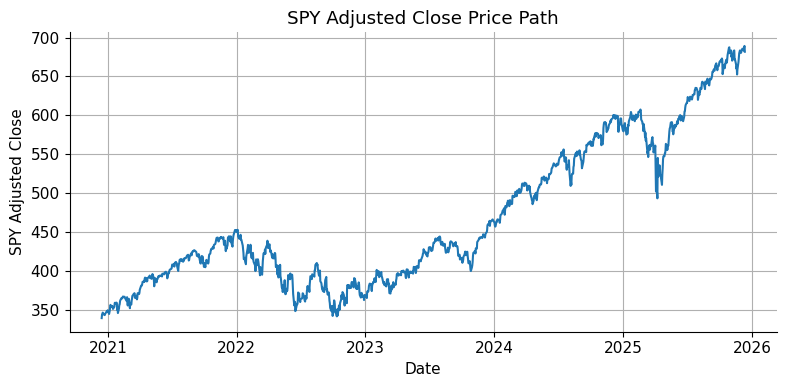

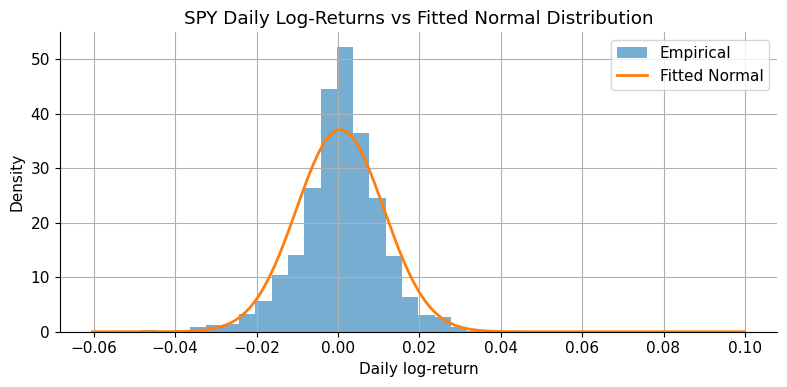


===== Daily statistics =====
mu_daily_hat    = 0.000554
sigma_daily_hat = 0.010762

===== Annualised (log) statistics =====
mu_annual_hat   = 0.1397
sigma_annual_hat = 0.1708  (annualised vol)


{'mu_daily_hat': np.float64(0.000554466113264076),
 'sigma_daily_hat': 0.010762334284289944,
 'mu_annual_hat': np.float64(0.13972546054254714),
 'sigma_annual_hat': np.float64(0.17084676025665307),
 'trading_days': 252}

In [110]:
# Cell 16: Analyze historical log-returns: estimate stats, plot, store

# Estimate historical daily mean and volatility, then annualise

trading_days = M  # typically 252 trading days in a year

# Daily stats (log-returns)
mu_daily_hat = log_returns.mean()
sigma_daily_hat = log_returns.std(ddof=1)  # sample std

# Annualised log-mean and volatility
# For log-returns: annual log-mean is approximately trading_days * mu_daily_hat
mu_annual_hat = trading_days * mu_daily_hat
sigma_annual_hat = sigma_daily_hat * np.sqrt(trading_days)

print("Estimated daily mean (mu_daily_hat):", mu_daily_hat)
print("Estimated daily vol  (sigma_daily_hat):", sigma_daily_hat)
print()
print("Estimated annual log-mean (mu_annual_hat):", mu_annual_hat)
print("Estimated annual vol      (sigma_annual_hat):", sigma_annual_hat)



# Plot historical SPY price path
plt.figure(figsize=(8, 4))
plt.plot(prices.index, prices["AdjClose"])
plt.xlabel("Date")
plt.ylabel("SPY Adjusted Close")
plt.title("SPY Adjusted Close Price Path")
plt.tight_layout()
plt.show()



# Histogram of daily log-returns with fitted Normal overlay

def normal_pdf(x, mu, sigma):
    return 1.0 / (np.sqrt(2 * np.pi) * sigma) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)

x_vals = np.linspace(log_returns.min(), log_returns.max(), 300)
pdf_vals = normal_pdf(x_vals, mu_daily_hat, sigma_daily_hat)

plt.figure(figsize=(8, 4))
plt.hist(log_returns, bins=40, density=True, alpha=0.6, label="Empirical")
plt.plot(x_vals, pdf_vals, linewidth=2, label="Fitted Normal")
plt.xlabel("Daily log-return")
plt.ylabel("Density")
plt.title("SPY Daily Log-Returns vs Fitted Normal Distribution")
plt.legend()
plt.tight_layout()
plt.show()



# Stats and storage for later

print("\n===== Daily statistics =====")
print(f"mu_daily_hat    = {mu_daily_hat:.6f}")
print(f"sigma_daily_hat = {sigma_daily_hat:.6f}")

print("\n===== Annualised (log) statistics =====")
print(f"mu_annual_hat   = {mu_annual_hat:.4f}")
print(f"sigma_annual_hat = {sigma_annual_hat:.4f}  (annualised vol)")

hist_stats = {
    "mu_daily_hat": mu_daily_hat,
    "sigma_daily_hat": sigma_daily_hat,
    "mu_annual_hat": mu_annual_hat,
    "sigma_annual_hat": sigma_annual_hat,
    "trading_days": trading_days,
}

hist_stats



In [111]:
# Cell 17: Reprice an All-Time-Money (ATM) European call using historical vol

# 1) Inputs from previous work
S0_hist    = float(prices["AdjClose"].iloc[-1])      # last observed price
sigma_annual_hat = float(hist_stats["sigma_annual_hat"])         # annualised historical volatility

K_hist = S0_hist         # ATM strike
T_hist = 0.5             # 0.5 years to maturity
r_hist = 0.03            # 3% risk-free rate

print("=== Parameters for historical-vol repricing ===")
print(f"S0_hist    = {S0_hist:.4f}")
print(f"K_hist     = {K_hist:.4f} (ATM)")
print(f"T_hist     = {T_hist} years")
print(f"r_hist     = {r_hist:.4f}")
print(f"sigma_annual_hat = {sigma_annual_hat:.4f}")
print("==============================================\n")

# 2) Black–Scholes analytic price with historical vol


sigma_sqrtT_hist = sigma_annual_hat * math.sqrt(T_hist)
d1_hist = (math.log(S0_hist / K_hist) + (r_hist + 0.5 * sigma_annual_hat**2) * T_hist) / sigma_sqrtT_hist
d2_hist = d1_hist - sigma_sqrtT_hist

call_bs_hist = (
    S0_hist * norm_cdf(d1_hist)
    - K_hist * math.exp(-r_hist * T_hist) * norm_cdf(d2_hist)
)

print(f"Black–Scholes call price (hist σ): {call_bs_hist:.4f}")

# 3) Monte Carlo price with same parameters (all *_hist names)

N_paths_hist = N_grid[-3]  # e.g., 200,000 paths
rng_hist = np.random.default_rng(rng_seed + 100)

Z_hist = rng_hist.standard_normal(N_paths_hist)

S_T_hist = S0_hist * np.exp(
    (r_hist - 0.5 * sigma_annual_hat**2) * T_hist
    + sigma_annual_hat * math.sqrt(T_hist) * Z_hist
)

payoffs_hist = np.maximum(S_T_hist - K_hist, 0.0)
discount_factor_hist = math.exp(-r_hist * T_hist)
discounted_payoffs_hist = discount_factor_hist * payoffs_hist

call_mc_hist = discounted_payoffs_hist.mean()
std_payoff_hist = discounted_payoffs_hist.std(ddof=1)
stderr_mc_hist = std_payoff_hist / math.sqrt(N_paths_hist)

print(f"Monte Carlo call price (hist σ):   {call_mc_hist:.4f}")
print(f"Monte Carlo standard error:        {stderr_mc_hist:.4f}")

diff_hist = call_mc_hist - call_bs_hist
print(f"\nMC - BS difference: {diff_hist:.4f}")
print(f"In MC std-error units: {diff_hist / stderr_mc_hist:.2f}")

# Store result for later tables / plots
repricing_hist = {
    "call_bs_hist": call_bs_hist,
    "call_mc_hist": call_mc_hist,
    "stderr_mc_hist": stderr_mc_hist,
    "params": {
        "S0_hist": S0_hist,
        "K_hist": K_hist,
        "T_hist": T_hist,
        "r_hist": r_hist,
        "sigma_annual_hat": sigma_annual_hat,
        "N_paths_hist": N_paths_hist,
    },
}

# Diagnostic using repricing_hist
p = repricing_hist["params"]

print("=== Historical ATM call repricing with σ_hist ===")
print(f"S0_hist:          {p['S0_hist']:.4f}")
print(f"K_hist:           {p['K_hist']:.4f}  (ATM)")
print(f"T_hist (years):   {p['T_hist']:.4f}")
print(f"r_hist:           {p['r_hist']:.4f}")
print(f"sigma_annual_hat:       {p['sigma_annual_hat']:.4f}")
print(f"N_paths_hist:     {p['N_paths_hist']:,d}")
print("----------------------------------------------")
print(f"BS price C_BS(σ_hist):   {repricing_hist['call_bs_hist']:.4f}")
print(
    f"MC price C_MC(σ_hist):   {repricing_hist['call_mc_hist']:.4f} "
    f"± {repricing_hist['stderr_mc_hist']:.4f}"
)
rel_diff = (repricing_hist["call_mc_hist"] - repricing_hist["call_bs_hist"]) / repricing_hist["call_bs_hist"]
print(f"Relative diff MC vs BS:  {rel_diff:+.3%}")
print("==============================================")



=== Parameters for historical-vol repricing ===
S0_hist    = 681.7600
K_hist     = 681.7600 (ATM)
T_hist     = 0.5 years
r_hist     = 0.0300
sigma_annual_hat = 0.1708

Black–Scholes call price (hist σ): 37.9187
Monte Carlo call price (hist σ):   37.8612
Monte Carlo standard error:        0.1226

MC - BS difference: -0.0575
In MC std-error units: -0.47
=== Historical ATM call repricing with σ_hist ===
S0_hist:          681.7600
K_hist:           681.7600  (ATM)
T_hist (years):   0.5000
r_hist:           0.0300
sigma_annual_hat:       0.1708
N_paths_hist:     200,000
----------------------------------------------
BS price C_BS(σ_hist):   37.9187
MC price C_MC(σ_hist):   37.8612 ± 0.1226
Relative diff MC vs BS:  -0.152%


Global Monte Carlo estimate (N_big_lln=200000): 38.0082
Analytic Black–Scholes price:                    37.9187


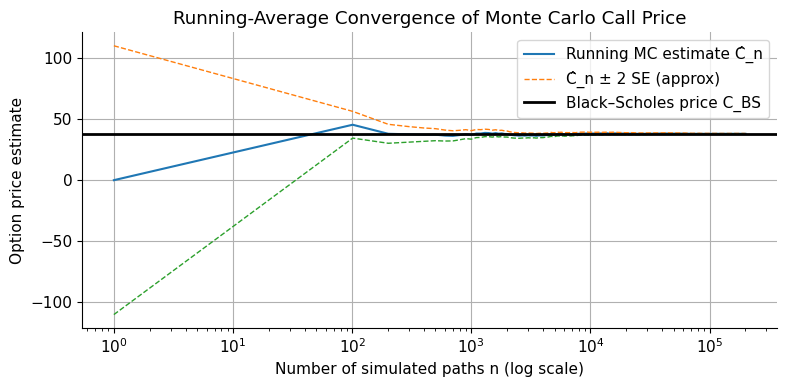

In [112]:
# Cell 18: Visualize running-average convergence of MC call price (historical vol)

# Uses existing: S0_hist, K_hist, T_hist, r_hist, sigma_annual_hat, call_bs_hist, np, plt

# 1) One big Monte Carlo experiment for the discounted payoff

N_big_lln = N_grid[-3]  # large simulation size for LLN illustration
rng_lln = np.random.default_rng(rng_seed + 200)

# Terminal prices under risk-neutral GBM with historical σ
Z_lln = rng_lln.standard_normal(N_big_lln)
S_T_lln = S0_hist * np.exp(
    (r_hist - 0.5 * sigma_annual_hat**2) * T_hist
    + sigma_annual_hat * np.sqrt(T_hist) * Z_lln
)

payoffs_lln = np.maximum(S_T_lln - K_hist, 0.0)
discount_factor_lln = np.exp(-r_hist * T_hist)
discounted_payoffs_lln = discount_factor_lln * payoffs_lln

# 2) Running average of the estimator Ĉ_n

n_vals_lln = np.arange(1, N_big_lln + 1)
running_avg_lln = np.cumsum(discounted_payoffs_lln) / n_vals_lln

# 3) Approximate standard error bands using global std σ̂_X

std_payoff_lln = discounted_payoffs_lln.std(ddof=1)
se_lln = std_payoff_lln / np.sqrt(n_vals_lln)

upper_band_lln = running_avg_lln + 2 * se_lln
lower_band_lln = running_avg_lln - 2 * se_lln

print(f"Global Monte Carlo estimate (N_big_lln={N_big_lln}): {running_avg_lln[-1]:.4f}")
print(f"Analytic Black–Scholes price:                    {call_bs_hist:.4f}")

# 4) Plot running average vs n with BS line and ±2 SE bands

# To avoid plotting 200k points, subsample for the graph
step_lln = max(1, N_big_lln // 2000)
idx_lln = slice(0, N_big_lln, step_lln)

plt.figure(figsize=(8, 4))
plt.plot(n_vals_lln[idx_lln], running_avg_lln[idx_lln], label="Running MC estimate Ĉ_n")
plt.plot(n_vals_lln[idx_lln], upper_band_lln[idx_lln], linestyle="--", linewidth=1, label="Ĉ_n ± 2 SE (approx)")
plt.plot(n_vals_lln[idx_lln], lower_band_lln[idx_lln], linestyle="--", linewidth=1)
plt.axhline(call_bs_hist, color="black", linewidth=2, label="Black–Scholes price C_BS")

plt.xscale("log")  # log scale to see early behaviour and long-run convergence
plt.xlabel("Number of simulated paths n (log scale)")
plt.ylabel("Option price estimate")
plt.title("Running-Average Convergence of Monte Carlo Call Price")
plt.legend()
plt.tight_layout()
plt.show()


In [113]:
# Cell 19: Fetch current market price of an ATM European call option (SPY)

today_mkt = prices.index[-1]          # last date in your historical data
S0_mkt    = float(S0_hist)            # underlying spot for comparison
T_target  = float(T_hist)             # target maturity in years (from your repricing cell)

# 1) Get SPY option expirations and pick the one closest to target date
spy_ticker = yf.Ticker("SPY")
expirations_mkt = pd.to_datetime(spy_ticker.options)

target_date_mkt = today_mkt + pd.to_timedelta(int(T_target * 365), unit="D")
expiry_mkt = min(expirations_mkt, key=lambda d: abs((d - target_date_mkt).days))

# 2) Get option chain for that expiry and select ATM call
opt_chain_mkt = spy_ticker.option_chain(expiry_mkt.strftime("%Y-%m-%d"))
calls_mkt = opt_chain_mkt.calls

# strike closest to current underlying
atm_idx_mkt = (calls_mkt["strike"] - S0_mkt).abs().idxmin()
atm_call_mkt = calls_mkt.loc[atm_idx_mkt]

strike_mkt = float(atm_call_mkt["strike"])
bid_mkt    = float(atm_call_mkt["bid"])
ask_mkt    = float(atm_call_mkt["ask"])
last_mkt   = float(atm_call_mkt["lastPrice"])

# mid price if bid/ask are usable, otherwise fall back to last
if bid_mkt > 0 and ask_mkt > 0:
    C_mkt = 0.5 * (bid_mkt + ask_mkt)
else:
    C_mkt = last_mkt

# actual T in years from today to this expiry
T_mkt = (expiry_mkt - today_mkt).days / 365.0

print("=== Market option (SPY call) ===")
print(f"Today (data end):         {today_mkt.date()}")
print(f"Underlying spot S0_mkt:   {S0_mkt:.2f}")
print(f"Expiry_mkt:               {expiry_mkt.date()}")
print(f"Time to maturity T_mkt:   {T_mkt:.3f} years")
print(f"Strike_mkt (≈ATM):        {strike_mkt:.2f}")
print(f"Market call price C_mkt:  {C_mkt:.2f}")
print("===============================")


=== Market option (SPY call) ===
Today (data end):         2025-12-12
Underlying spot S0_mkt:   681.76
Expiry_mkt:               2026-06-18
Time to maturity T_mkt:   0.515 years
Strike_mkt (≈ATM):        680.00
Market call price C_mkt:  38.98


In [114]:
# Cell 20: Monte Carlo pricing function for European call with parameters

# Early in the notebook: toy MC pricer bound to global parameters (Cell 4)
# mc_european_call_price_param is the general version for flexible inputs (market section).

def mc_european_call_price_param(
    S0: float, K: float, T: float, r: float, sigma: float,
    N_paths: int, rng: np.random.Generator
) -> tuple[float, float]:
    """
    Monte Carlo price and standard error for a European call.

    Returns
    -------
    price_mc : float
        Monte Carlo estimate of the call price.
    se_mc : float
        Standard error of the estimate.
    """
    if sigma <= 0 or T <= 0 or N_paths <= 0:
        # Degenerate cases: just return intrinsic or zero variance
        intrinsic = max(S0 - K * math.exp(-r * T), 0.0)
        return intrinsic, 0.0

    Z = rng.standard_normal(N_paths)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * math.sqrt(T) * Z)

    payoffs = np.maximum(ST - K, 0.0)
    disc_factor = math.exp(-r * T)
    disc_payoffs = disc_factor * payoffs

    price_mc = float(np.mean(disc_payoffs))
    se_mc = float(np.std(disc_payoffs, ddof=1) / math.sqrt(N_paths))
    return price_mc, se_mc


In [ ]:
# Cell 21: Compare market price vs model prices using historical volatility


# Model BS price using historical volatility
call_bs_hist_mkt, _, _ = bs_call_price(S0_mkt, strike_mkt, r_hist, sigma_annual_hat, T_mkt)

# Model MC price using historical volatility
N_paths_mkt = N_grid[-3]  # e.g., 200,000 paths
rng_mkt = np.random.default_rng(rng_seed + 300)
call_mc_hist_mkt, se_mc_hist_mkt = mc_european_call_price_param(
    S0_mkt, strike_mkt, T_mkt, r_hist, sigma_annual_hat, N_paths_mkt, rng_mkt
)

print("=== Model vs Market (using σ_hist) ===")
print(f"Market price C_mkt:                  {C_mkt:.4f}")
print(f"Model BS price C_BS(σ_hist):         {call_bs_hist_mkt:.4f}")
print(f"Model MC price C_MC(σ_hist):         {call_mc_hist_mkt:.4f}")
print(f"   MC standard error:                {se_mc_hist_mkt:.4f}")
print("--------------------------------------")
print(f"Difference (C_mkt - C_BS):           {C_mkt - call_bs_hist_mkt:.4f}")
print(f"Difference (C_mkt - C_MC):           {C_mkt - call_mc_hist_mkt:.4f}")
print("======================================")


=== Model vs Market (using σ_hist) ===
Market price C_mkt:                  32.3350
Model BS price C_BS(σ_hist):         38.6679
Model MC price C_MC(σ_hist):         38.7136
   MC standard error:                0.1269
--------------------------------------
Difference (C_mkt - C_BS):           -6.3329
Difference (C_mkt - C_MC):           -6.3786


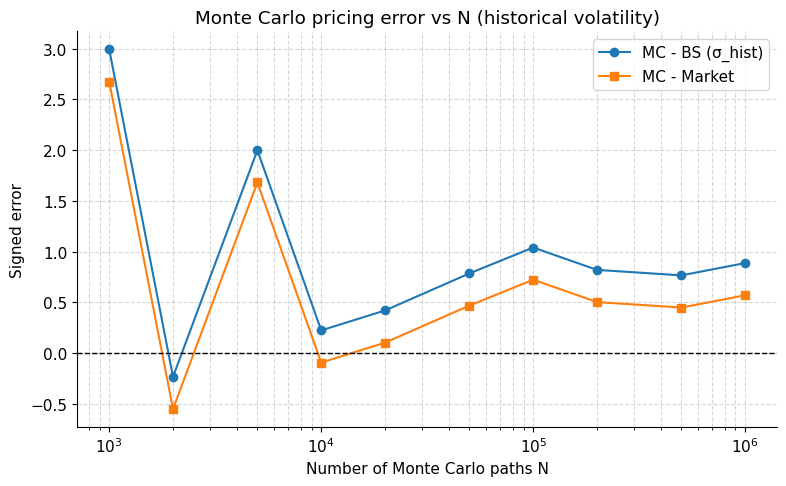

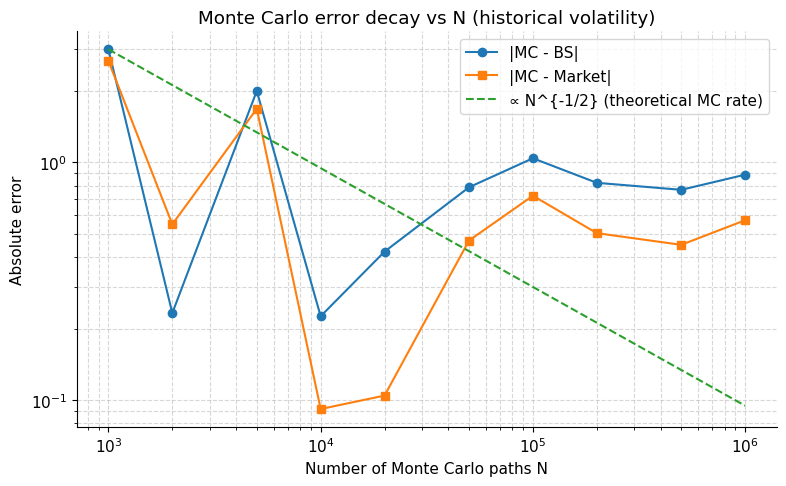

In [115]:
# Cell 22: Convergence study of MC call price vs N (historical vol)


errors_bs = []   # C_MC(N) - C_BS
errors_mkt = []  # C_MC(N) - C_mkt
ses_mc = []      # MC standard errors

for N_paths in N_grid:
    # New RNG per N for independence; seed shift keeps runs reproducible
    rng_tmp = np.random.default_rng(rng_seed + 400 + int(N_paths))

    price_mc_N, se_mc_N = mc_european_call_price_param(
        S0_mkt, strike_mkt, T_mkt, r_hist, sigma_annual_hat,
        N_paths, rng_tmp
    )

    errors_bs.append(price_mc_N - call_bs_hist_mkt)
    errors_mkt.append(price_mc_N - C_mkt)
    ses_mc.append(se_mc_N)

errors_bs = np.array(errors_bs)
errors_mkt = np.array(errors_mkt)
ses_mc = np.array(ses_mc)

# Plot 1: signed errors vs N
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(N_grid, errors_bs, marker="o", label="MC - BS (σ_hist)")
ax.plot(N_grid, errors_mkt, marker="s", label="MC - Market")

ax.axhline(0.0, color="black", linewidth=1, linestyle="--")

ax.set_xscale("log")
ax.set_xlabel("Number of Monte Carlo paths N")
ax.set_ylabel("Signed error")
ax.set_title("Monte Carlo pricing error vs N (historical volatility)")
ax.legend()
ax.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Plot 2: |error| vs N in log–log, with N^{-1/2} reference
fig, ax = plt.subplots(figsize=(8, 5))

abs_err_bs = np.abs(errors_bs)
abs_err_mkt = np.abs(errors_mkt)

ax.loglog(N_grid, abs_err_bs, marker="o", label="|MC - BS|")
ax.loglog(N_grid, abs_err_mkt, marker="s", label="|MC - Market|")

# Reference line ~ N^{-1/2} scaled to the first BS error
ref_const = abs_err_bs[0] * np.sqrt(N_grid[0])
ax.loglog(
    N_grid,
    ref_const / np.sqrt(N_grid),
    linestyle="--",
    label="∝ N^{-1/2} (theoretical MC rate)"
)

ax.set_xlabel("Number of Monte Carlo paths N")
ax.set_ylabel("Absolute error")
ax.set_title("Monte Carlo error decay vs N (historical volatility)")
ax.legend()
ax.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [116]:
# Cell 23: Implied volatility calculation via bisection method

def implied_vol_call_bisection(
    C_target: float,
    S0: float,
    K: float,
    T: float,
    r: float,
    sigma_low: float = 1e-4,
    sigma_high: float = 3.0,
    tol: float = 1e-6,
    max_iter: int = 100
) -> float:
    """
    Implied volatility for a European call via bisection.

    C_target: market call price
    S0, K, T, r: option parameters
    sigma_low, sigma_high: initial volatility bracket
    """

    price_low, _, _  = bs_call_price(S0, K, r, sigma_low, T)
    price_high, _, _ = bs_call_price(S0, K, r, sigma_high, T)

    # crude sanity check: if target outside [low, high], method may fail
    if not (price_low <= C_target <= price_high):
        print("Warning: C_target not bracketed by prices at sigma_low/high.")

    sigma_lo, sigma_hi = sigma_low, sigma_high

    for _ in range(max_iter):
        sigma_mid = 0.5 * (sigma_lo + sigma_hi)
        price_mid, _, _ = bs_call_price(S0, K, r, sigma_mid, T)

        if abs(price_mid - C_target) < tol:
            return sigma_mid

        if price_mid < C_target:
            sigma_lo = sigma_mid
        else:
            sigma_hi = sigma_mid

    # If we exit the loop, return the best midpoint
    return 0.5 * (sigma_lo + sigma_hi)


sigma_impl_mkt = implied_vol_call_bisection(
    C_target=C_mkt,
    S0=S0_mkt,
    K=strike_mkt,
    T=T_mkt,
    r=r_hist
)

print("=== Historical vs Implied Vol ===")
print(f"Historical volatility σ_hist:   {sigma_annual_hat:.4f}")
print(f"Implied volatility σ_impl_mkt:  {sigma_impl_mkt:.4f}")
print(f"Difference σ_impl - σ_hist:     {sigma_impl_mkt - sigma_annual_hat:.4f}")
print("=================================")


=== Historical vs Implied Vol ===
Historical volatility σ_hist:   0.1708
Implied volatility σ_impl_mkt:  0.1683
Difference σ_impl - σ_hist:     -0.0026


In [117]:
# Cell 24: Summary table comparing model prices vs market

p = repricing_hist["params"]

summary_rows = []

# Row 1: historical model with T_hist
summary_rows.append({
    "Scenario":        "Model @ T_hist (σ_hist)",
    "S0":              p["S0_hist"],
    "K":               p["K_hist"],
    "T_years":         p["T_hist"],
    "sigma":           p["sigma_annual_hat"],
    "Price_BS":        repricing_hist["call_bs_hist"],
    "Price_MC":        repricing_hist["call_mc_hist"],
    "SE_MC":           repricing_hist["stderr_mc_hist"],
    "Source":          "Historical σ plugged into BS/MC",
})

# Row 2: model using σ_hist but with actual market maturity T_mkt
summary_rows.append({
    "Scenario":        "Model @ T_mkt (σ_hist)",
    "S0":              S0_mkt,
    "K":               strike_mkt,
    "T_years":         T_mkt,
    "sigma":           sigma_annual_hat,
    "Price_BS":        call_bs_hist_mkt,
    "Price_MC":        call_mc_hist_mkt,
    "SE_MC":           se_mc_hist_mkt,
    "Source":          "Same σ_hist, real option maturity",
})

# Row 3: actual market price and implied vol
summary_rows.append({
    "Scenario":        "Market",
    "S0":              S0_mkt,
    "K":               strike_mkt,
    "T_years":         T_mkt,
    "sigma":           sigma_impl_mkt,
    "Price_BS":        C_mkt,      # treat market price as 'truth'
    "Price_MC":        None,
    "SE_MC":           None,
    "Source":          "Observed option price, implied σ",
})

summary_df = pd.DataFrame(summary_rows)

# add differences vs market where defined
summary_df["Diff_mkt_minus_BS"] = summary_df["Price_BS"] - C_mkt
summary_df["Diff_mkt_minus_MC"] = summary_df["Price_MC"] - C_mkt

print("=== Summary: model using σ_hist vs market ===")
print(summary_df.to_string(index=False, float_format="{:.4f}".format))


=== Summary: model using σ_hist vs market ===
               Scenario       S0        K  T_years  sigma  Price_BS  Price_MC  SE_MC                            Source  Diff_mkt_minus_BS  Diff_mkt_minus_MC
Model @ T_hist (σ_hist) 681.7600 681.7600   0.5000 0.1708   37.9187   37.8612 0.1226   Historical σ plugged into BS/MC            -1.0663            -1.1238
 Model @ T_mkt (σ_hist) 681.7600 680.0000   0.5151 0.1708   38.6679   38.7136 0.1269 Same σ_hist, real option maturity            -0.3171            -0.2714
                 Market 681.7600 680.0000   0.5151 0.1683   38.9850       NaN    NaN  Observed option price, implied σ             0.0000                NaN
